In [7]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
from sklearn.metrics import confusion_matrix, classification_report, jaccard_score, precision_score
import yaml
import pandas as pd
pd.__version__

'1.0.3'

In [10]:
val = pickle.load(open('cluster_val.pkl','rb'))
y_val = pickle.load(open('cluster_y_val.pkl','rb'))
preds = pickle.load(open('FINAL/FINAL-preds.pkl','rb'))
test = pickle.load(open('FINAL/test.pkl','rb'))
test_rot = pickle.load(open('FINAL/test_rotated.pkl','rb'))
y_test = pickle.load(open('FINAL/y_test.pkl','rb'))
y_test_rot = pickle.load(open('FINAL/y_test_rotated.pkl','rb'))
test_preds = pickle.load(open('FINAL/FINAL-test-preds.pkl','rb'))
test_preds_rot = pickle.load(open('FINAL/FINAL-test-rot-preds.pkl','rb'))
test.shape, test_preds.shape, y_test.shape

((175, 256, 256, 1), (175, 256, 256), (175, 256, 256, 1))

In [11]:
counts = np.unique(y_test, return_counts=True)[1]
counts/counts.sum()

array([0.9335417 , 0.01961426, 0.04684405])

In [12]:
counts = np.unique(test_preds, return_counts=True)[1]
counts/counts.sum()

array([0.96000244, 0.00719491, 0.03280265])

In [18]:
print(jaccard_score(y_test.flatten(),test_preds.flatten(),average='macro'))
print(jaccard_score(y_test.flatten(),test_preds.flatten(),average='micro'))
print(classification_report(y_test.flatten(),test_preds.flatten(),digits=3))

0.5489486578667422
0.9167817427073823
              precision    recall  f1-score   support

           0      0.966     0.993     0.979  10706603
           1      0.747     0.274     0.401    224952
           2      0.739     0.517     0.608    537245

    accuracy                          0.957  11468800
   macro avg      0.817     0.595     0.663  11468800
weighted avg      0.951     0.957     0.950  11468800



In [16]:
y_test_rot[y_test_rot==3] = 0
print(jaccard_score(y_test_rot.flatten(),test_preds_rot.flatten(),average='macro'))
print(jaccard_score(y_test_rot.flatten(),test_preds_rot.flatten(),average='micro'))
print(classification_report(y_test_rot.flatten(),test_preds_rot.flatten(),digits=3))

0.5212025984935825
0.9056241817275053
              precision    recall  f1-score   support

           0      0.963     0.989     0.976  10702462
           1      0.712     0.249     0.369    233242
           2      0.659     0.480     0.555    533096

    accuracy                          0.950  11468800
   macro avg      0.778     0.573     0.634  11468800
weighted avg      0.943     0.950     0.944  11468800



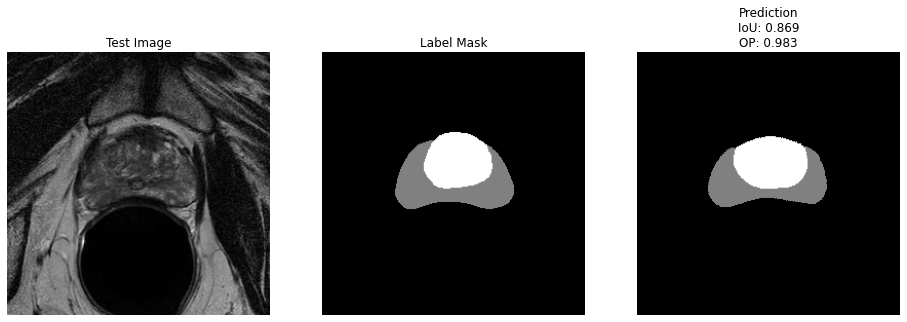

In [28]:
#for i in range(175):
idx=111
plt.figure(figsize=(16,9))
plt.subplot(1,3,1)
plt.title('Test Image')
plt.imshow(test[idx,:,:,0],cmap='gray')
plt.axis('off')
plt.subplot(1,3,2)
plt.imshow(y_test[idx,:,:,0],cmap='gray')
plt.axis('off')
plt.title(f'Label Mask')
plt.subplot(1,3,3)
plt.imshow(test_preds[idx,:,:],cmap='gray')
plt.axis('off')
plt.title(f"Prediction\nIoU: {jaccard_score(y_test[idx,:,:,0].flatten(),test_preds[idx,:,:].flatten(),average='macro') :.3f}\nOP: {precision_score(y_test[idx,:,:,0].flatten(),test_preds[idx,:,:].flatten(),average='micro') :.3f}")
plt.savefig(f'../visualization/example.png',bbox_inches='tight',dpi=100)
plt.show()

In [7]:
models = ['FOC-DEEP', 'FINAL', 'FINAL-2']
for m in models:
    print(m)
    path = "./"+m+"/eval.yaml"
    results = yaml.safe_load(open(path,'rb'))
    print(f"OP: {results['val-data']['accuracy'] :.3f}")
    print(f"PC: {results['val-data']['macro avg']['precision']:.3f}")
    print(f"Jaccard-score: {results['val-jaccard-score']:.3f}")
    print('\n')

FOC-DEEP
OP: 0.968
PC: 0.845
Jaccard-score: 0.655


FINAL
OP: 0.969
PC: 0.850
Jaccard-score: 0.646


FINAL-2
OP: 0.966
PC: 0.873
Jaccard-score: 0.602


